# Generic E-commerce Scraper → Data Mining → Backend

Works on **any** e-commerce site: site-specific knowledge (URL, CSS
selectors, field extractors, backend mapping) lives in **one declaration
cell**. Swap `ACTIVE_SITE` to scrape a different shop — no other cell
needs to change.

```
Declaration cell (site profile + mining config)
        ↓
Scrape (generic, profile-driven)  →  RawProduct records
        ↓
Detail stage (follow each product's link / slug)  →  full description,
specs table, gallery images, rating for every product
        ↓
Data mining (clean → engineer → EDA → models)   ← config-driven
        ↓
Enrich records with mined values (price imputation, features, segments)
        ↓
POST to backend (skip-if-exists, throttled, retried)
```

## Cell 0 — Declaration (the only cell you edit per site)

`SITE_PROFILES` maps a site name to everything that differs between
shops; `MINING_CONFIG` decides how the mined data is built. Adding a new
site = adding a profile entry + setting `ACTIVE_SITE`.

Each profile may also declare a `detail` block: selectors for the product's
**own page**, fetched after the listing stage by following the `url` that was
collected per card (the same slug the backend dedupes on).

In [ ]:
# ============================================================
# DECLARATION — edit this cell to support a new site / schema
# ============================================================

BACKEND_URL = "http://localhost:8001"
API_PREFIX = "/api/v1"
PRODUCT_ENDPOINT = f"{BACKEND_URL}{API_PREFIX}/product"

ACTIVE_SITE = "startech"          # <- switch sites here

SITE_PROFILES = {
    "startech": {

        # --- what to scrape ---
        "name": "startech",
        "list_urls": [
            "https://www.startech.com.bd/mobile-phone",
        ],
        "max_pages": 10,
        "pagination_param": "page",

        # --- where the data lives in the listing card ---
        "item_selector": ".p-item",
        "fields": {
            "name":        {"selector": ".p-item-name a", "attr": "text"},
            "url":         {"selector": ".p-item-name a", "attr": "href"},
            "price":       {"selector": "meta[itemprop='price']", "attr": "content"},
            "image":       {"selector": "img[itemprop='image']", "attr": "src"},
            "availability": {"selector": "meta[itemprop='availability']", "attr": "content"},
        },
        "spec_selectors": {          # optional key: value lists inside the card
            "specifications": ".short-description li",
        },
        "external_id_pattern": r"cart\.add\(['\"]([^'\"]+)",   # searched in onclick attrs

        # --- detail page: the product's own page, reached via the url/slug
        #     collected from the listing card (fetched after the listing stage) ---
        "detail": {
            "enabled": True,
            "concurrency": 4,   # parallel detail fetches (shared limiter still applies)
            "fields": {
                "name":              {"selector": "h1.product-name", "attr": "text"},
                "price":             {"selector": "meta[itemprop='price']", "attr": "content"},
                "availability":      {"selector": "link[itemprop='availability']", "attr": "href"},
                "description":       {"selector": ".full-description", "attr": "text", "separator": " "},
                "short_description": {"selector": ".short-description", "attr": "text", "separator": " "},
                "rating":            {"selector": ".average-rating", "attr": "text", "regex": r"(\d+(?:\.\d+)?)"},
                "rating_count":      {"selector": "section#write-review h2", "attr": "text", "regex": r"\((\d+)\)"},
            },
            # key/value <tr> tables on the detail page -> merged into specifications
            "spec_tables": {
                "specifications": "section#specification table.data-table tr",
            },
            # gallery images -> merged into the payload's images list
            "gallery": {"selector": ".product-images img", "attr": "src"},
        },

        # --- how raw values are cleaned into canonical types ---
        "normalizers": {
            "price": "bdt_price",          # 'Tk 41,000' / '41000' -> float
            "availability": "schema_org",  # 'https://schema.org/InStock' -> 'InStock'
        },

        # --- which fields the mining stage should derive (regex on name) ---
        "derive": {
            "capacity_tons": {"pattern": r"(\d(?:\.\d)?)\s*-?\s*Ton", "as": "float"},
            "is_inverter":   {"pattern": r"inverter", "negative": r"non-inverter"},
            "has_wifi":      {"pattern": r"(wifi|wi-fi)"},
        },
        "brand_from_name": ["gree", "haier", "midea", "tcl", "hisense",
                            "xiaomi", "beko", "singer", "smart", "walton", "daikin"],
    },

    # ---- second site, proving the config-driven design ----
    "techland": {
        "name": "techland",
        "list_urls": [
            "https://www.techlandbd.com/air-conditioner",
        ],
        "max_pages": 2,
        "pagination_param": "page",
        "item_selector": "div.product-layout",
        "fields": {
            "name":   {"selector": "h4 a", "attr": "text"},
            "url":    {"selector": "h4 a", "attr": "href"},
            "price":  {"selector": ".price", "attr": "text"},
            "image":  {"selector": "img", "attr": "src"},
        },
        "spec_selectors": {},
        "external_id_pattern": None,

        # NOTE: techland's detail selectors are best-effort guesses — the site
        # answers 403 to scripted requests, so verify them on the first real run.
        "detail": {
            "enabled": True,
            "concurrency": 3,
            "fields": {
                "description": {"selector": "#tab-description", "attr": "text", "separator": " "},
            },
            "spec_tables": {
                "specifications": "table.attribute tr",
            },
            "gallery": {
                "selector": ".product-images img, .additional-images img, .thumbnail img",
                "attr": "src",
            },
        },

        "normalizers": {"price": "bdt_price"},
        "derive": {
            "capacity_tons": {"pattern": r"(\d(?:\.\d)?)\s*-?\s*Ton", "as": "float"},
            "is_inverter":   {"pattern": r"inverter", "negative": r"non-inverter"},
        },
        "brand_from_name": ["gree", "haier", "midea", "tcl", "panasonic",
                            "sharp", "walton", "vision"],
    },
}

SITE = SITE_PROFILES[ACTIVE_SITE]

MINING_CONFIG = {
    "dedupe_on": "productSlug",
    "drop_rows_missing": ["price"],                 # cannot model without the target
    "price_outlier_method": "iqr_winsorize",        # cap, don't delete
    "price_outlier_multiplier": 1.5,
    "numeric_fill_strategy": "median",
    "unknown_label": "Unknown",
    # mined values that get attached to every record before POSTing
    "enrich_fields": ["price_imputed", "capacity_tons", "is_inverter", "has_wifi", "segment"],
    "kmeans_k": 3,
    "random_state": 42,
}

print(f"Active site: {ACTIVE_SITE} -> {SITE['list_urls']}")
print(f"Mining config: {MINING_CONFIG}")

FIELD_MAP = {
    # backend field  <-  record field (or callable)
    "name": "name",
    "productSlug": "productSlug",
    # missing prices are NaN (not None) — use pd.notna, then the imputed value
    "price": lambda rec: rec["price"] if pd.notna(rec["price"]) else rec["price_imputed"],
    "currency": lambda rec: "BDT",
    # detail-page copy ("" rather than None — Joi does not accept null)
    "description": lambda rec: str(rec.get("description") or ""),
    "shortDescription": lambda rec: str(rec.get("short_description") or ""),
    # cover image first, then every gallery image from the detail page (deduped)
    "images": lambda rec: [
        {"url": url, "alt": rec.get("name") or "", "isPrimary": i == 0, "sortOrder": i}
        for i, url in enumerate(dict.fromkeys(
            [u for u in [rec.get("image"), *(rec.get("images") or [])] if u]
        ))
    ],
    # rating parsed from the detail page (0 when the product has no reviews)
    "rating": lambda rec: {
        "average": float(rec["rating"]) if pd.notna(rec.get("rating")) else 0,
        "count": int(float(rec["rating_count"])) if pd.notna(rec.get("rating_count")) else 0,
    },
    "specifications": lambda rec: {
        **(rec.get("specifications") or {}),
        "capacity_tons": rec["capacity_tons"],
        "segment": rec["segment"],
    },
    "attributes": lambda rec: {
        "availability": rec["availability"],
        "price_imputed": bool(pd.isna(rec["price"]) and rec["price_imputed"] > 0),
        "is_inverter": rec.get("is_inverter"),
        "has_wifi": rec.get("has_wifi"),
        "mined_version": "v1",
    },
    "tags": lambda rec: [SITE["name"], "mined"],
    # external ids only exist when a site exposes them — send "" rather than
    # null, because the backend schema requires a string here
    "sources": lambda rec: [{
        "name": SITE["name"],
        "externalId": rec.get("external_id") or "",
        "url": rec.get("url") or "",
    }],
    "status": lambda rec: "draft",
}


Active site: startech -> ['https://www.startech.com.bd/']
Mining config: {'dedupe_on': 'productSlug', 'drop_rows_missing': ['price'], 'price_outlier_method': 'iqr_winsorize', 'price_outlier_multiplier': 1.5, 'numeric_fill_strategy': 'median', 'unknown_label': 'Unknown', 'enrich_fields': ['price_imputed', 'capacity_tons', 'is_inverter', 'has_wifi', 'segment'], 'kmeans_k': 3, 'random_state': 42}


## Cell 1 — Imports (shared by scraping and mining)

In [33]:
import asyncio
import random
import re
import time

import numpy as np
import pandas as pd
import httpx
import matplotlib.pyplot as plt
from aiolimiter import AsyncLimiter
from pydantic import BaseModel, Field
from selectolax.parser import HTMLParser
from tenacity import (
    retry,
    retry_if_exception,
    retry_if_exception_type,
    stop_after_attempt,
    wait_exponential,
)
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    r2_score,
)
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## Cell 2 — Throttled HTTP client + generic profile-driven scraper

`ProfileScraper` reads only from `SITE`: selectors, attribute names,
normalizers and derive patterns. Nothing here knows which site it is on.

`scrape_all()` walks the listing pages; `scrape_details()` then follows every
record's own `url` (slug) and merges the product page's fields, spec table and
gallery using the profile's `detail` config.

In [34]:
class EcommerceHttpClient:

    def __init__(self, requests_per_minute=20, min_delay=2, max_delay=4, max_retries=3):
        self.limiter = AsyncLimiter(requests_per_minute, 60)
        self.min_delay = min_delay
        self.max_delay = max_delay
        self.last_request = 0
        self.max_retries = max_retries
        self.client = httpx.AsyncClient(
            timeout=30,
            follow_redirects=True,
            headers={"User-Agent": "EcommerceImporter/1.0 (product data importer)"},
        )

    async def _pacing(self):
        async with self.limiter:
            elapsed = time.monotonic() - self.last_request
            delay = random.uniform(self.min_delay, self.max_delay)
            if elapsed < delay:
                await asyncio.sleep(delay - elapsed)
            self.last_request = time.monotonic()

    async def get(self, url):
        for attempt in range(1, self.max_retries + 1):
            await self._pacing()
            response = await self.client.get(url)
            if response.status_code != 429 or attempt == self.max_retries:
                break
            retry_after = response.headers.get("Retry-After")
            try:
                wait = float(retry_after) if retry_after else 60
            except ValueError:
                wait = 60
            print(f"429 received — waiting {wait}s before retry {attempt + 1}/{self.max_retries}")
            await asyncio.sleep(wait)
        response.raise_for_status()
        return response

    async def post(self, url, json=None):
        await self._pacing()
        return await self.client.post(url, json=json)

    async def close(self):
        await self.client.aclose()


def normalize_value(kind, raw):
    """Canonical value transformations, chosen by the site profile."""
    if raw is None:
        return None
    if kind == "bdt_price":
        digits = re.sub(r"[^0-9.]", "", str(raw).split("/")[0])
        return float(digits) if digits else None
    if kind == "schema_org":
        return str(raw).rstrip("/").split("/")[-1] or None
    return raw


def extract_spec_list(list_text):
    """"Key: Value" lines -> dict."""
    specs = {}
    for line in str(list_text).splitlines():
        line = line.strip()
        if ":" in line:
            key, value = line.split(":", 1)
            specs[key.strip()] = value.strip()
    return specs


class ProfileScraper:
    """Drives any site described by a SITE_PROFILES entry."""

    def __init__(self, client, site):
        self.client = client
        self.site = site

    def _absolutize(self, url):
        if not url:
            return None
        if url.startswith("http"):
            return url
        base = re.match(r"(https?://[^/]+)", self.site["list_urls"][0]).group(1)
        return base + url

    @staticmethod
    def _has_value(value):
        """True when a freshly parsed value is worth writing onto a record."""
        if value is None:
            return False
        if isinstance(value, str):
            return bool(value.strip())
        if isinstance(value, (list, dict, tuple)):
            return bool(value)
        return not (isinstance(value, float) and pd.isna(value))

    def _extract_field(self, root, field, spec):
        """selector + attr (+ optional regex / separator) + profile normalizer."""
        el = root.css_first(spec["selector"])
        if el is None:
            return None
        attr = spec.get("attr", "text")
        if attr == "text":
            raw = el.text(strip=True, separator=spec.get("separator", ""))
        else:
            raw = el.attributes.get(attr)
        if spec.get("regex") and raw:
            match = re.search(spec["regex"], raw)
            if not match:
                return None
            raw = match.group(1) if match.groups() else match.group(0)
        if spec.get("separator") and isinstance(raw, str):
            raw = re.sub(r"\s+", " ", raw).strip()
        kind = self.site.get("normalizers", {}).get(field)
        return normalize_value(kind, raw)

    def parse_card(self, node):
        record = {
            field: self._extract_field(node, field, spec)
            for field, spec in self.site["fields"].items()
        }

        record["url"] = self._absolutize(record.get("url"))
        record["image"] = self._absolutize(record.get("image"))

        for target, list_selector in self.site.get("spec_selectors", {}).items():
            texts = [li.text(strip=True) for li in node.css(list_selector)]
            record[target] = extract_spec_list("\n".join(t for t in texts if t))

        if self.site.get("external_id_pattern"):
            onclick_node = node.css_first("[onclick]")
            onclick = (onclick_node.attributes.get("onclick", "") if onclick_node else "") or ""
            match = re.search(self.site["external_id_pattern"], onclick)
            record["external_id"] = match.group(1) if match else None
        else:
            record["external_id"] = None

        if not record.get("name"):
            return None
        record["productSlug"] = re.sub(r"[^a-z0-9]+", "-", record["name"].lower()).strip("-")
        return record

    async def scrape_category(self, url):
        response = await self.client.get(url)
        tree = HTMLParser(response.text)
        records = []
        for node in tree.css(self.site["item_selector"]):
            record = self.parse_card(node)
            if record:
                records.append(record)
        return records

    async def scrape_all(self):
        all_records = []
        for list_url in self.site["list_urls"]:
            for page in range(1, self.site.get("max_pages", 1) + 1):
                url = list_url if page == 1 else f"{list_url}?{self.site.get('pagination_param', 'page')}={page}"
                print(f"Scraping page {page}: {url}")
                page_records = await self.scrape_category(url)
                if not page_records:
                    break
                all_records.extend(page_records)
        return all_records

    def parse_detail(self, tree):
        """Product page -> dict of fields / spec pairs / gallery images,
        chosen entirely by the profile's `detail` config."""
        cfg = self.site.get("detail") or {}
        detail = {}

        for field, spec in (cfg.get("fields") or {}).items():
            value = self._extract_field(tree, field, spec)
            if self._has_value(value):
                detail[field] = value

        for target, table_selector in (cfg.get("spec_tables") or {}).items():
            pairs = {}
            for row in tree.css(table_selector):
                cells = [c for c in (cell.text(strip=True) for cell in row.css("td, th")) if c]
                if len(cells) >= 2:  # single-cell rows are section headings
                    pairs[cells[0]] = cells[1]
            if pairs:
                detail[target] = pairs

        gallery = cfg.get("gallery")
        if gallery:
            attr = gallery.get("attr", "src")
            urls, seen = [], set()
            for node in tree.css(gallery["selector"]):
                raw = node.text(strip=True) if attr == "text" else node.attributes.get(attr)
                url = self._absolutize(raw)
                if url and url not in seen:
                    seen.add(url)
                    urls.append(url)
            if urls:
                detail["images"] = urls

        return detail

    async def _fetch_detail_page(self, url):
        """GET one product page and parse it (shared by repeated listings)."""
        response = await self.client.get(url)
        return self.parse_detail(HTMLParser(response.text))

    def _apply_detail(self, record, detail):
        for field, value in detail.items():
            if isinstance(value, dict):  # detail spec table extends the card specs
                record[field] = {**(record.get(field) or {}), **value}
            else:
                record[field] = value

    async def scrape_detail(self, record):
        """GET one product page (record['url']) and merge its full data."""
        url = record.get("url")
        if not url:
            return False
        detail = await self._fetch_detail_page(url)
        self._apply_detail(record, detail)
        record["detail_url"] = url
        return True

    async def scrape_details(self, records, concurrency=None):
        """Detail stage: fetch every record's own product page (throttled,
        partially parallel, per-product failures isolated). The same product
        listed on several pages is only fetched once."""
        cfg = self.site.get("detail") or {}
        if not cfg or not cfg.get("enabled", True):
            print("Detail stage: profile has no enabled `detail` config \u2014 using listing data only.")
            return records

        semaphore = asyncio.Semaphore(max(1, int(concurrency or cfg.get("concurrency", 3))))
        stats = {"fetched": 0, "failed": 0, "reused": 0}

        async def fetch_page(url):
            try:
                async with semaphore:
                    detail = await self._fetch_detail_page(url)
                stats["fetched"] += 1
                return detail
            except Exception as exc:  # one dead page must not kill the run
                stats["failed"] += 1
                return exc

        # one task per unique product URL, so repeat listings share the result
        urls = [rec.get("url") for rec in records]
        unique_urls = [u for u in dict.fromkeys(urls) if u]
        results = dict(zip(unique_urls, await asyncio.gather(*(fetch_page(u) for u in unique_urls))))

        seen = set()
        for record, url in zip(records, urls):
            if not url:
                continue
            if url in seen:
                stats["reused"] += 1
            seen.add(url)
            result = results.get(url)
            if isinstance(result, dict):
                self._apply_detail(record, result)
                record["detail_url"] = url
            elif result is not None:
                record["detail_error"] = repr(result)
                print(f"DETAIL FAILED: {record.get('name')} \u2014 {result!r}")

        print(
            f"Detail stage: {stats['fetched']} product pages fetched, "
            f"{stats['reused']} repeat listings reused, {stats['failed']} failed "
            f"({len(records)} records)"
        )
        return records


## Cell 3 — Run the scraper (uses ACTIVE_SITE only)

In [35]:
http_client = EcommerceHttpClient()
scraper = ProfileScraper(http_client, SITE)

records = await scraper.scrape_all()

print(f"\nScraped {len(records)} records from {ACTIVE_SITE}")
if records:
    print(records[0])

Scraping page 1: https://www.startech.com.bd/
Scraping page 2: https://www.startech.com.bd/?page=2
Scraping page 3: https://www.startech.com.bd/?page=3

Scraped 60 records from startech
{'name': 'AMD Ryzen 3 3200G Budget Desktop PC With Monitor', 'url': 'https://www.startech.com.bd/amd-ryzen-3-3200g-budget-desktop-pc', 'price': None, 'image': None, 'availability': None, 'specifications': {}, 'external_id': None, 'productSlug': 'amd-ryzen-3-3200g-budget-desktop-pc-with-monitor'}


## Cell 4 — Detail stage: follow every product's own page (slug → full data)

The listing stage only gives card fields plus a link. Each record already
carries its product `url` — the same slug the backend dedupes on — so this
stage GETs every product page and merges in:

* `description` / `short_description` — the long copy that only exists on the detail page
* `specifications` from the detail page's key/value table (merged over the card specs)
* `images` gallery, `rating`, `rating_count`, plus fresher price/availability

Driven entirely by `SITE["detail"]` (skipped when a profile has none), still
throttled by the shared HTTP client, with per-product failure isolation.
Mining and sending both run **after** this stage.


In [36]:
# Follow each record's own product URL (the slug) and merge the full page
# data BEFORE any mining or backend work happens.
records = await scraper.scrape_details(records)

full = sum(1 for rec in records if rec.get("detail_url"))
print(f"\nDetail stage: {full}/{len(records)} products now carry their own page data")

if records:
    sample = records[0]
    print("Sample detail data:")
    for key in ("description", "short_description", "images", "rating", "rating_count", "specifications"):
        if key not in sample:
            continue
        value = sample[key]
        if isinstance(value, str) and len(value) > 100:
            value = value[:100] + "…"
        elif isinstance(value, dict):
            value = f"{len(value)} keys — e.g. {dict(list(value.items())[:3])}"
        elif isinstance(value, list):
            value = f"{len(value)} image(s)"
        print(f"  {key}: {value}")


Detail stage: 20 product pages fetched, 40 repeat listings reused, 0 failed (60 records)

Detail stage: 60/60 products now carry their own page data
Sample detail data:
  description: AMD Ryzen 3 3200G Budget Desktop PC With Monitor The AMD Ryzen 3 3200G Budget Desktop PC With Monito…
  short_description: Key Features Model: Ryzen 3 3200G Budget Desktop PC AMD Ryzen 3 3200G Processor with Radeon RX Vega …
  images: 1 image(s)
  rating_count: 0
  specifications: 6 keys — e.g. {'Processor': 'AMD Ryzen 3 3200G Processor with Radeon RX Vega 8 Graphics03 Years Warranty (No Warranty for Fan or Cooler)', 'Motherboard': 'XENTHRA XN-B450M-VH-PRO AMD AM4 mATX Motherboard03 Years Warranty', 'RAM': 'AITC Kingsman Innovator 8GB DDR4 3200MHz Desktop RAM BlackLifetime warranty'}


## Cell 5 — Data mining on the scraped records

Everything below is driven by `MINING_CONFIG` / `SITE["derive"]` —
reusable for any site's records.

In [37]:
def records_to_frame(records, site):
    """Raw scrape records -> tidy analysis frame, deriving the
    profile-defined features from the product name."""
    rows = []

    for rec in records:
        name = rec.get("name") or ""
        name_lower = name.lower()
        row = {
            "name": name,
            "productSlug": rec.get("productSlug"),
            "price": rec.get("price"),
            "image": rec.get("image"),
            "url": rec.get("url"),
            "availability": rec.get("availability"),
            "specifications": rec.get("specifications") or {},
            "external_id": rec.get("external_id"),
            # ---- fields contributed by the detail stage ----
            "description": rec.get("description") or "",
            "short_description": rec.get("short_description") or "",
            "images": rec.get("images") or [],
            "rating": pd.to_numeric(rec.get("rating"), errors="coerce"),
            "rating_count": pd.to_numeric(rec.get("rating_count"), errors="coerce"),
        }

        for feature, spec in (site.get("derive") or {}).items():
            if "negative" in spec:
                row[feature] = bool(
                    re.search(spec["pattern"], name_lower)
                    and not re.search(spec["negative"], name_lower)
                )
            elif spec.get("as") == "float":
                # typed numeric feature — NaN when the pattern does not match
                match = re.search(spec["pattern"], name, re.I)
                row[feature] = float(match.group(1)) if match else np.nan
            else:
                # presence flag — always a proper boolean, False when absent
                row[feature] = bool(re.search(spec["pattern"], name_lower))

        brand_tokens = site.get("brand_from_name") or []
        row["brand"] = next(
            (token.title() for token in re.findall(r"[A-Za-z]+", name_lower)
             if token in brand_tokens),
            "Unknown",
        )
        rows.append(row)

    return pd.DataFrame(rows)


df_raw = records_to_frame(records, SITE)
print(f"Raw analysis frame: {df_raw.shape}")
df_raw.head()

Raw analysis frame: (60, 17)


,name,productSlug,price,image,url,availability,specifications,external_id,description,short_description,images,rating,rating_count,capacity_tons,is_inverter,has_wifi,brand
0,AMD Ryzen 3 3200G Budget Desktop PC With Monitor,amd-ryzen-3-3200g-budget-desktop-pc-with-monitor,33999.0,None,https://www.startech.com.bd/amd-ryzen-3-3200g-...,InStock,{'Processor': 'AMD Ryzen 3 3200G Processor wit...,None,AMD Ryzen 3 3200G Budget Desktop PC With Monit...,Key Features Model: Ryzen 3 3200G Budget Deskt...,[https://www.startech.com.bd/image/cache/catal...,NaN,0,NaN,False,False,Unknown
1,AMD Ryzen 7 5700G Desktop PC,amd-ryzen-7-5700g-desktop-pc,56850.0,None,https://www.startech.com.bd/amd-ryzen-7-5700g-...,InStock,{'Processor': 'AMD Ryzen 7 5700G Processor wit...,None,AMD Ryzen 7 5700G Custom Desktop PC The AMD Ry...,Key Features Model: Ryzen 7 5700G Custom Deskt...,[https://www.startech.com.bd/image/cache/catal...,NaN,0,NaN,False,False,Unknown
2,Intel Core i7 14700 14th Gen Gaming Desktop PC,intel-core-i7-14700-14th-gen-gaming-desktop-pc,159999.0,None,https://www.startech.com.bd/intel-core-i7-1470...,InStock,{'Processor': 'Intel Core i7 14700 14th Gen Ra...,None,Intel Core i7 14700 14th Gen Gaming Desktop PC...,Key Features Model: 14th Gen Gaming Desktop PC...,[https://www.startech.com.bd/image/cache/catal...,NaN,0,NaN,False,False,Unknown
3,Omron HEM-7121J Digital Blood Pressure Monitor,omron-hem-7121j-digital-blood-pressure-monitor,3750.0,None,https://www.startech.com.bd/omron-hem-7121j-di...,InStock,{},None,Omron HEM-7121J Digital Blood Pressure Monitor...,Key Features Model: HEM-7121J Hypertension Ind...,[https://www.startech.com.bd/image/cache/catal...,NaN,0,NaN,False,False,Unknown
4,"Haier 43P7 PRO 43"" 4K HQLED Smart Google TV",haier-43p7-pro-43-4k-hqled-smart-google-tv,45900.0,None,https://www.startech.com.bd/haier-43p7-pro-43-...,InStock,"{'Display Type': 'HQLED', 'Screen Size': '43""'...",None,"Haier 43P7 PRO 43"" 4K HQLED Smart Google TV Th...","Key Features Model: 43P7 PRO Display: 43"" 4K U...",[https://www.startech.com.bd/image/cache/catal...,5.0,2,NaN,False,False,Haier


## Cell 6 — Cleaning (config-driven)

In [38]:
df = df_raw.copy()
report = []

# 1. duplicates (same product listed on several pages)
before = len(df)
df = df.drop_duplicates(subset=MINING_CONFIG["dedupe_on"]).reset_index(drop=True)
report.append(("Duplicates removed", before - len(df)))

# 2. rows missing the modelling target are KEPT (they will receive an
#    imputed price in the enrichment step) but excluded from training
missing_target = int(df[MINING_CONFIG["drop_rows_missing"]].isna().any(axis=1).sum())
report.append(("Rows missing price (kept, will be imputed)", missing_target))

# 3. price outliers — IQR winsorization
mult = MINING_CONFIG["price_outlier_multiplier"]
q1, q3 = df["price"].quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - mult * iqr, q3 + mult * iqr
outliers = int(((df["price"] < lo) | (df["price"] > hi)).sum())
df["price"] = df["price"].clip(lo, hi)
report.append(("Price outliers capped", outliers))

# 4. brand labels — recover + canonicalize
canonical = {}
for label in df["brand"].unique():
    canonical[label] = label if label != "Unknown" else MINING_CONFIG["unknown_label"]
df["brand"] = df["brand"].replace(canonical)

# 5. availability — normalize text, keep gaps visible
CANONICAL_AVAILABILITY = {
    "instock": "InStock",
    "in stock": "InStock",
    "outofstock": "OutOfStock",
    "out of stock": "OutOfStock",
    "preorder": "PreOrder",
}

def _norm_avail(v):
    key = str(v).strip().lower()
    if key in ("", "none", "nan"):
        return MINING_CONFIG["unknown_label"]
    return CANONICAL_AVAILABILITY.get(key, str(v).strip())

df["availability"] = df["availability"].map(_norm_avail)
report.append(
    ("Availability labels", sorted(df["availability"].unique()))
)

print("Cleaning report:")
for label, n in report:
    print(f"  - {label}: {n}")
print(f"\nClean frame: {df.shape}")

Cleaning report:
  - Duplicates removed: 40
  - Rows missing price (kept, will be imputed): 0
  - Price outliers capped: 2
  - Availability labels: ['InStock']

Clean frame: (20, 17)


## Cell 7 — EDA

In [39]:
print(df[["price"]].describe().round(2))
print()
numeric_cols = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c]) and c != "price"]
print("Numeric feature columns:", numeric_cols)
print()
print("Brand frequency:")
print(df["brand"].value_counts())
print()
print("Availability:")
print(df["availability"].value_counts())

           price
count      20.00
mean    79409.46
std     62662.37
min       792.39
25%     35499.75
50%     63249.50
75%    107500.00
max    215500.38

Numeric feature columns: ['rating', 'rating_count', 'capacity_tons', 'is_inverter', 'has_wifi']

Brand frequency:
brand
Unknown    17
Haier       1
Smart       1
Xiaomi      1
Name: count, dtype: int64

Availability:
availability
InStock    20
Name: count, dtype: int64


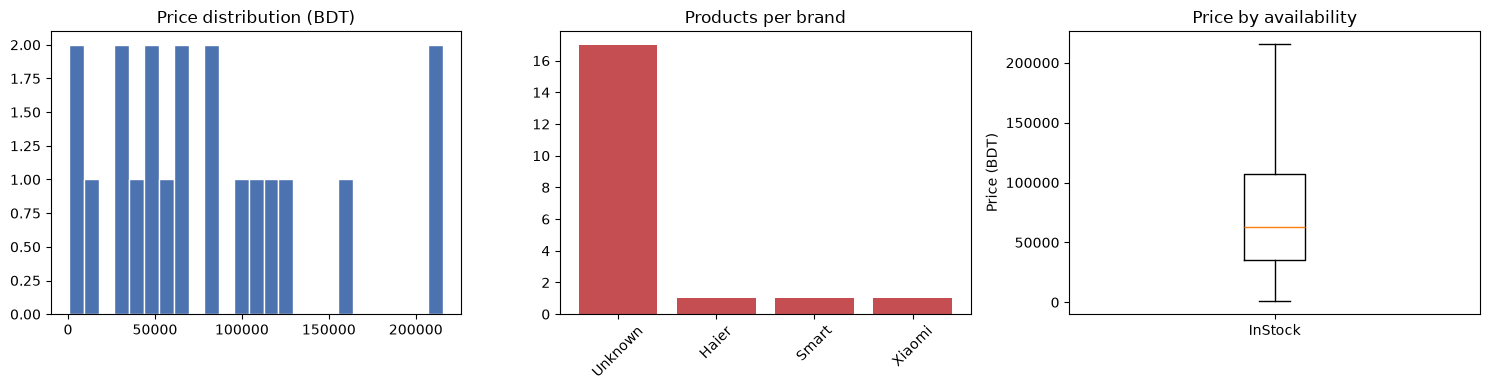

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(df["price"], bins=25, color="#4c72b0", edgecolor="white")
axes[0].set_title("Price distribution (BDT)")

brand_counts = df["brand"].value_counts()
axes[1].bar(brand_counts.index, brand_counts.values, color="#c44e52")
axes[1].set_title("Products per brand")
axes[1].tick_params(axis="x", rotation=45)

groups = [g["price"].values for _, g in df.groupby("availability")]
axes[2].boxplot(groups, tick_labels=list({g: i for i, g in enumerate(sorted(set(df["availability"])))}.keys()))
axes[2].set_title("Price by availability")
axes[2].set_ylabel("Price (BDT)")

plt.tight_layout()
plt.show()

## Cell 8 — Preprocessing + regression (price prediction)

Numeric profile-derived features + one-hot categoricals, then
LinearRegression vs RandomForestRegressor under 5-fold CV.

In [41]:
# price imputation model — later used to enrich records that had no price
NUMERIC_FEATURES = [
    c for c in df.columns
    if pd.api.types.is_numeric_dtype(df[c]) and c not in ("price",)
]
CATEGORICAL_FEATURES = ["brand", "availability"]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("impute", SimpleImputer(strategy=MINING_CONFIG["numeric_fill_strategy"])),
                ("scale", StandardScaler()),
            ]),
            NUMERIC_FEATURES,
        ),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
    ]
)

model_df = df.dropna(subset=["price"])
X = model_df[NUMERIC_FEATURES + CATEGORICAL_FEATURES]
y = model_df["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=MINING_CONFIG["random_state"]
)

models = {
    "LinearRegression": LinearRegression(),
    "RandomForest": RandomForestRegressor(n_estimators=300, random_state=MINING_CONFIG["random_state"]),
}

results = {}
for model_name, model in models.items():
    pipeline = Pipeline([("prep", preprocessor), ("model", model)])
    cv_r2 = cross_val_score(pipeline, X_train, y_train, cv=5, scoring="r2")
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    results[model_name] = {
        "cv_r2_mean": cv_r2.mean(),
        "test_r2": r2_score(y_test, y_pred),
        "test_mae": mean_absolute_error(y_test, y_pred),
    }
    print(f"{model_name:18s} CV R2 = {cv_r2.mean():.3f}  Test R2 = {results[model_name]['test_r2']:.3f}  MAE = {results[model_name]['test_mae']:,.0f} BDT")

best_name = max(results, key=lambda k: results[k]["test_r2"])
print(f"\nBest price model: {best_name}")

# refit on ALL priced rows -> this is the imputer used to enrich unpriced records
price_model = Pipeline([("prep", preprocessor), ("model", models[best_name])])
price_model.fit(X, y)

C:\Users\squal\AppData\Roaming\Python\Python312\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['capacity_tons']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\squal\AppData\Roaming\Python\Python312\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['capacity_tons']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\squal\AppData\Roaming\Python\Python312\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['capacity_tons']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\squal\AppData\Roaming\Python\Python312\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['capacity_tons']. At least one non-missing valu

LinearRegression   CV R2 = -1.165  Test R2 = -15.759  MAE = 72,362 BDT


C:\Users\squal\AppData\Roaming\Python\Python312\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['capacity_tons']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\squal\AppData\Roaming\Python\Python312\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['capacity_tons']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\squal\AppData\Roaming\Python\Python312\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['capacity_tons']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\squal\AppData\Roaming\Python\Python312\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['capacity_tons']. At least one non-missing valu

RandomForest       CV R2 = -5.839  Test R2 = -19.132  MAE = 83,805 BDT

Best price model: LinearRegression


C:\Users\squal\AppData\Roaming\Python\Python312\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['capacity_tons']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\squal\AppData\Roaming\Python\Python312\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['capacity_tons']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['rating','rating_count','capacity_tons',...,'has_wifi','brand', 'availability']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsi

## Cell 9 — Classification (auto-skipped when no boolean derive feature exists)

Uses the first boolean feature from `SITE["derive"]` as the target.
If the active site derives none, the section skips itself —
another site-profile-driven branch.

In [42]:
boolean_features = [
    f for f, spec in (SITE.get("derive") or {}).items() if "negative" in spec or "as" not in spec
]

if boolean_features:
    clf_target = boolean_features[0]
    print(f"Classification target from profile: {clf_target}")

    clf_features = ["brand", "availability", "price"] + [
        c for c in NUMERIC_FEATURES if c != clf_target
    ]
    Xc = model_df[clf_features]
    yc = model_df[clf_target].astype(int)

    if yc.nunique() < 2:
        print(f"'{clf_target}' has a single class in this dataset — skipping classification")
    else:
        Xc_train, Xc_test, yc_train, yc_test = train_test_split(
            Xc, yc, test_size=0.2, random_state=MINING_CONFIG["random_state"], stratify=yc
        )

        clf_preprocessor = ColumnTransformer(
            transformers=[
                ("num", Pipeline([
                    ("impute", SimpleImputer(strategy=MINING_CONFIG["numeric_fill_strategy"])),
                    ("scale", StandardScaler()),
                ]), [c for c in clf_features if c in NUMERIC_FEATURES]),
                ("cat", OneHotEncoder(handle_unknown="ignore"), ["brand", "availability"]),
            ]
        )

        classifiers = {
            "LogisticRegression": LogisticRegression(max_iter=1000),
            "RandomForest": RandomForestClassifier(n_estimators=300, random_state=MINING_CONFIG["random_state"]),
        }

        fitted_classifiers = {}
        for clf_name, clf in classifiers.items():
            clf_pipeline = Pipeline([("prep", clf_preprocessor), ("model", clf)])
            clf_pipeline.fit(Xc_train, yc_train)
            fitted_classifiers[clf_name] = clf_pipeline
            print(f"\n=== {clf_name} — accuracy: {accuracy_score(yc_test, clf_pipeline.predict(Xc_test)):.3f} ===")
            print(classification_report(yc_test, clf_pipeline.predict(Xc_test), zero_division=0))

        best_clf_name = max(
            fitted_classifiers,
            key=lambda n: accuracy_score(yc_test, fitted_classifiers[n].predict(Xc_test)),
        )
        print(f"Best classifier: {best_clf_name}")

        cm = confusion_matrix(yc_test, fitted_classifiers[best_clf_name].predict(Xc_test))
        fig, ax = plt.subplots(figsize=(4.5, 4))
        im = ax.imshow(cm, cmap="Blues")
        ax.set_title(f"Confusion matrix — {best_clf_name}")
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")
        for (i, j), value in np.ndenumerate(cm):
            ax.text(j, i, str(value), ha="center", va="center")
        plt.colorbar(im)
        plt.tight_layout()
        plt.show()
else:
    print("No boolean derive feature in this site profile — classification skipped")

Classification target from profile: is_inverter
'is_inverter' has a single class in this dataset — skipping classification


## Cell 10 — Clustering — market segments (elbow + K-Means)

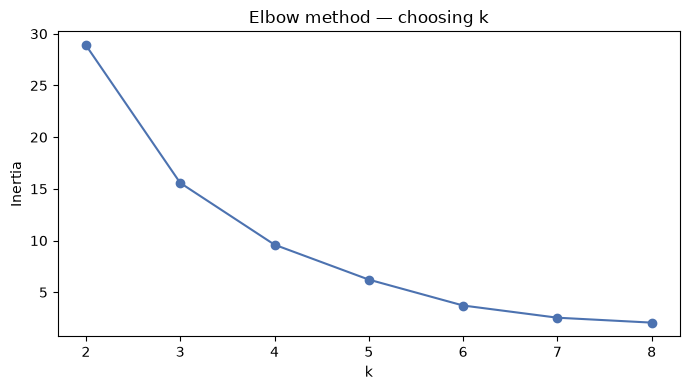

K-Means on columns: ['price', 'rating', 'rating_count', 'is_inverter', 'has_wifi'] (k=3)
Cluster profiles (means):
             price  rating  rating_count  is_inverter  has_wifi  count
segment                                                               
0           792.39     4.0          5.00          0.0       0.0      1
1         47741.42     5.0          0.33          0.0       0.0     12
2        144928.54     5.0          1.29          0.0       0.0      7


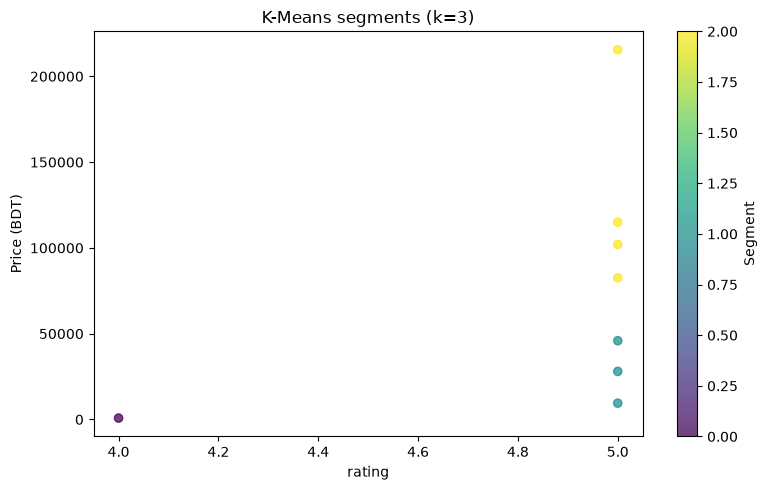

In [43]:
cluster_cols = ["price"] + NUMERIC_FEATURES

# numeric coercion + drop derive features that never matched on this site
# (e.g. no product name contains 'Ton' -> capacity_tons is all-NaN)
X_cl = model_df[cluster_cols].apply(pd.to_numeric, errors="coerce")
X_cl = X_cl.dropna(axis=1, how="all")

if X_cl.shape[1] < 2 or X_cl.shape[0] < 4:

    print("Not enough usable numeric data for clustering — skipped")

else:

    imputer = SimpleImputer(strategy=MINING_CONFIG["numeric_fill_strategy"])
    X_imp = imputer.fit_transform(X_cl)

    X_scaled = StandardScaler().fit_transform(X_imp)

    inertias = []
    k_range = range(2, 9)

    for k in k_range:
        km = KMeans(n_clusters=k, random_state=MINING_CONFIG["random_state"], n_init=10)
        km.fit(X_scaled)
        inertias.append(km.inertia_)

    plt.figure(figsize=(7, 4))
    plt.plot(list(k_range), inertias, marker="o", color="#4c72b0")
    plt.title("Elbow method — choosing k")
    plt.xlabel("k")
    plt.ylabel("Inertia")
    plt.tight_layout()
    plt.show()

    K_BEST = max(2, min(MINING_CONFIG["kmeans_k"], X_cl.shape[0] - 1))

    kmeans = KMeans(n_clusters=K_BEST, random_state=MINING_CONFIG["random_state"], n_init=10)
    model_df = model_df.copy()
    model_df["segment"] = kmeans.fit_predict(X_scaled)

    profile = (
        model_df.groupby("segment")[list(X_cl.columns)]
        .mean()
        .round(2)
    )
    profile["count"] = model_df["segment"].value_counts().sort_index()
    print(f"K-Means on columns: {list(X_cl.columns)} (k={K_BEST})")
    print("Cluster profiles (means):")
    print(profile)

    plot_col = next(
        (
            col
            for col in X_cl.columns
            if col != "price" and model_df[col].notna().any()
        ),
        "price",
    )

    fig, ax = plt.subplots(figsize=(8, 5))
    scatter = ax.scatter(
        model_df[plot_col],
        model_df["price"],
        c=model_df["segment"],
        cmap="viridis",
        alpha=0.75,
    )
    ax.set_xlabel(plot_col)
    ax.set_ylabel("Price (BDT)")
    ax.set_title(f"K-Means segments (k={K_BEST})")
    plt.colorbar(scatter, label="Segment")
    plt.tight_layout()
    plt.show()

## Cell 11 — Attach mined values back onto the raw records

The backend no longer receives raw scrapes: each record gets
`mined` — imputed price where missing, profile-derived features,
and its cluster segment. Mined values are marked with `_mined: true`
so the backend/front-end can tell them from scraped facts.

In [44]:
# price imputation for records that were missing it
unpriced = df[df["price"].isna()]
imputed_count = 0

if len(unpriced):
    imputed_prices = price_model.predict(unpriced[NUMERIC_FEATURES + CATEGORICAL_FEATURES])
    df.loc[unpriced.index, "price_imputed"] = np.round(imputed_prices, -2)
    imputed_count = int(df["price_imputed"].notna().sum())
else:
    df["price_imputed"] = np.nan

df["price_imputed"] = df["price_imputed"].fillna(0).astype(float)

# map segment back onto every record row by slug
segment_by_slug = model_df.set_index("productSlug")["segment"].to_dict()
df["segment"] = df["productSlug"].map(segment_by_slug).astype("float")

print(f"Records enriched. Price imputations: {imputed_count}, records with segment: {int(df['segment'].notna().sum())}")
df[["name", "price", "price_imputed", "segment"]].head()

Records enriched. Price imputations: 0, records with segment: 20


,name,price,price_imputed,segment
0,AMD Ryzen 3 3200G Budget Desktop PC With Monitor,33999.0,0.0,1.0
1,AMD Ryzen 7 5700G Desktop PC,56850.0,0.0,1.0
2,Intel Core i7 14700 14th Gen Gaming Desktop PC,159999.0,0.0,2.0
3,Omron HEM-7121J Digital Blood Pressure Monitor,3750.0,0.0,1.0
4,"Haier 43P7 PRO 43"" 4K HQLED Smart Google TV",45900.0,0.0,1.0


## Cell 12 — Config-driven backend mapping + send

`FIELD_MAP` decides how a record becomes the backend Product schema —
change it here, not in the send logic. Mined fields ride along in
`attributes` / `specifications` and are flagged `_mined`.

In [45]:
def is_retryable_error(exc):
    """Retry only transient failures: 5xx, 429, network errors."""

    if isinstance(exc, httpx.HTTPStatusError):
        status = exc.response.status_code if exc.response is not None else 0
        return status >= 500 or status == 429

    return isinstance(exc, httpx.HTTPError)


def _clean_nan(value):
    """NaN -> None everywhere, so the payload is always valid JSON
    (json.dumps would emit bare NaN, which Express/body-parser rejects)."""
    if isinstance(value, float) and pd.isna(value):
        return None
    if isinstance(value, dict):
        return {k: _clean_nan(v) for k, v in value.items()}
    if isinstance(value, list):
        return [_clean_nan(v) for v in value]
    return value


def record_to_payload(record):
    payload = {}
    for backend_field, source in FIELD_MAP.items():
        payload[backend_field] = source(record) if callable(source) else record.get(source)
    payload["sku"] = ""
    payload["barcode"] = ""
    payload["mpn"] = ""
    payload["gtin"] = ""
    return _clean_nan(payload)


@retry(
    stop=stop_after_attempt(3),
    wait=wait_exponential(multiplier=1, min=1, max=10),
    retry=retry_if_exception(is_retryable_error),
    reraise=True,
)
async def send_product_to_backend(record, http_client):
    payload = record_to_payload(record)
    response = await http_client.post(PRODUCT_ENDPOINT, json=payload)
    response.raise_for_status()
    return response.json()


async def product_exists(http_client, product_slug):
    try:
        response = await http_client.get(f"{PRODUCT_ENDPOINT}/slug/{product_slug}")
        return response.status_code == 200
    except httpx.HTTPStatusError as exc:
        if exc.response is not None and exc.response.status_code == 404:
            return False
        raise


async def send_all_products_to_backend(records_df, http_client):
    sent, skipped, failed = [], [], []
    total = len(records_df)

    for i, row in enumerate(records_df.to_dict("records"), start=1):
        product_slug = row["productSlug"]
        label = f"[{i}/{total}]"

        try:
            if await product_exists(http_client, product_slug):
                skipped.append(row["name"])
                print(f"{label} SKIPPED (already in backend): {row['name']}")
                continue

            await send_product_to_backend(row, http_client)
            sent.append(row["name"])
            print(f"{label} OK: {row['name']}")

        except httpx.HTTPStatusError as exc:
            status = exc.response.status_code if exc.response is not None else None
            if status == 409:
                skipped.append(row["name"])
                print(f"{label} SKIPPED (duplicate): {row['name']}")
            else:
                # surface the backend's own message (Joi / AppError) if it sent one
                try:
                    reason = exc.response.json().get("message")
                except Exception:
                    reason = None
                detail = f"{status}: {reason}" if reason else repr(exc)
                failed.append((row["name"], detail))
                print(f"{label} FAILED: {row['name']} — {detail}")
        except httpx.HTTPError as exc:
            failed.append((row["name"], repr(exc)))
            print(f"{label} FAILED: {row['name']} — {exc!r}")

    return sent, skipped, failed


print(f"Sender ready for site '{SITE['name']}' — FIELD_MAP fields: {list(FIELD_MAP)}")

Sender ready for site 'startech' — FIELD_MAP fields: ['name', 'productSlug', 'price', 'currency', 'description', 'shortDescription', 'images', 'rating', 'specifications', 'attributes', 'tags', 'sources', 'status']


## Cell 13 — Send mined records to the backend

In [46]:
sent, skipped, failed = await send_all_products_to_backend(df, http_client)

print()
print(f"Sent: {len(sent)}, Skipped: {len(skipped)}, Failed: {len(failed)}")

if failed:
    print("Failed products:")
    for name, err in failed:
        print(f"  - {name}: {err}")

await http_client.close()

[1/20] OK: AMD Ryzen 3 3200G Budget Desktop PC With Monitor
[2/20] OK: AMD Ryzen 7 5700G Desktop PC
[3/20] OK: Intel Core i7 14700 14th Gen Gaming Desktop PC
[4/20] OK: Omron HEM-7121J Digital Blood Pressure Monitor
[5/20] OK: Haier 43P7 PRO 43" 4K HQLED Smart Google TV
[6/20] OK: Anker SOLIX C1000 Gen 2 2000W Portable Power Station
[7/20] OK: Hithium HeroEE MaxPower 8 AIO 5kW Portable Power Station
[8/20] OK: Pigeon PG352/00 8L Air Fryer
[9/20] OK: MSI BZ09 Core i5-14400 DDR4 Mini Tower Brand PC
[10/20] OK: AOC 25G4K 24.5" 420Hz FHD Fast IPS Gaming Monitor
[11/20] OK: MSI Modern MD272UPSW 27" 60Hz 4K UHD Smart Monitor
[12/20] OK: Xiaomi H40 Robot Vacuum Cleaner
[13/20] FAILED: MSI Cyborg 15 Black Edition A13UC Core i5 13th Gen RTX 3050 15.6" FHD Gaming Laptop — HTTPStatusError("Server error '500 Internal Server Error' for url 'http://localhost:8001/api/v1/product'\nFor more information check: https://developer.mozilla.org/en-US/docs/Web/HTTP/Status/500")
[14/20] FAILED: Lenovo IdeaPad

## Course learning outcomes — now site-agnostic

| Stage | Where it lives | Technique |
|---|---|---|
| Site declaration | Cell 0 | selectors, normalizers, derive patterns per site |
| Data collection | Cells 2–3 | generic profile-driven async scraper |
| Detail pages | Cell 4 | follow each product's URL/slug, merge its full data |
| Cleaning | Cell 6 | config-driven dedup, winsorization, label canonicalization |
| EDA | Cell 7 | distributions, frequencies, boxplots |
| Regression / imputation | Cell 8 | CV model comparison, then reuse as price imputer |
| Classification | Cell 9 | auto-selected boolean target, guarded when absent |
| Clustering | Cell 10 | elbow + K-Means segments |
| Enrichment | Cell 11 | mined values attached to raw records |
| Backend mapping | Cell 12 | `FIELD_MAP` — schema mapping without touching send logic |
| Sending | Cell 13 | skip-if-exists, 409-tolerant, transient-only retries |

**Pipeline:** any site → one profile → scrape → detail → mine → enrich → backend.